In [32]:
"""
code used to DEA the testing, validation, training datasets

"""

'\nThis notebook is used to DEA the testing, validation, training datasets\n\n'

In [33]:
import tensorflow as tf
import os
import random
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pickle
from matplotlib.colors import LogNorm
from lo_tools import Lfun, obs_functions
from lo_tools import plotting_functions as pfun
Ldir = Lfun.Lstart()

In [34]:
plt.rcdefaults()

In [35]:
plt.rcParams.update({
    'axes.labelsize': 12,          # Labels font size
    'xtick.labelsize': 11,         # X-axis ticks font size
    'ytick.labelsize': 11,         # Y-axis ticks font size
    # 'axes.labelweight': 'bold',    # Bold axis labels
    'xtick.direction': 'out',       # X-axis tick direction
    'ytick.direction': 'out',       # Y-axis tick direction
    'font.size': 10,               # Default font size for other text
})

In [36]:
SEED = 4

os.environ["PYTHONHASHSEED"] = str(SEED)

np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

tf.config.experimental.enable_op_determinism()

### Prepare for the data

In [37]:
# where to put output figures
fig_dir0 = Ldir['LOo'] / 'LO_bias_corr' / 'plots' / 'keras'
Lfun.make_dir(fig_dir0)

in_dir = Ldir['LOo'] / 'LO_bias_corr' / 'data'/ 'processed'
otype_list = ['bottle', 'ctd']
gtx = 'cas2k_v4_lo2b'


add_hake_hpic_trawl = True
add_hake_hpic = False
cast_split =True
remove_dfo = True

full_z = True
filter_z = False

for otype in otype_list:
    if otype == 'bottle':
        in_fn = in_dir / ('combined_' + otype + '_all_' + '1993-2021' + '.p')
        bottle = pickle.load(open(in_fn, 'rb'))
        # Filter by z
        if filter_z:
            Z ='30-800 m'
            mask = (bottle['obs']['z'] >= -800) & (bottle['obs']['z'] <= -30)
            bottle['obs'] = bottle['obs'][mask]
            bottle[gtx] = bottle[gtx][mask]

        elif not filter_z and not full_z:
            Z ='below 30m'
            mask = (bottle['obs']['z'] <= -30)
            bottle['obs'] = bottle['obs'][mask]
            bottle[gtx] = bottle[gtx][mask]

        elif full_z:
            Z ='full_depth'

        # bottle['obs'] = obs_functions.renumber_cid(bottle['obs'])
        # bottle[gtx] = obs_functions.renumber_cid(bottle[gtx])
        # calculate DO bias
        bias_bottle = bottle[gtx]['DO (uM)'] - bottle['obs']['DO (uM)']

    if otype == 'ctd':
        if add_hake_hpic:
            runame = 'with_hake_hpic'
            in_fn = in_dir / ('combined_' + otype + '_all_' + '1998-2022' + '.p') # added Hake+IPHC
            if cast_split:
                name = 'cid_split'
            else:
                name = ''
            fig_dir = fig_dir0/ runame / name
            Lfun.make_dir(fig_dir)
        elif add_hake_hpic_trawl:
            runame = 'with_hake_hpic_trawl'
            in_fn = in_dir / ('combined_' + otype + '_all_' + '1998-2022' + '.p') # added Hake+IPHC
            fig_dir = fig_dir0/ runame
            Lfun.make_dir(fig_dir)
        else:
            in_fn = in_dir / ('combined_' + otype + '_' + '1998-2021' + '.p') # old
            runame = ''
            fig_dir = fig_dir0/ runame
            Lfun.make_dir(fig_dir)
        ctd = pickle.load(open(in_fn, 'rb'))
        if remove_dfo:
            # Drop rows where 'source' is equal to 'dfo1'
            ctd['obs'] = ctd['obs'][ctd['obs']['source'] != 'dfo1']
            ctd[gtx] = ctd[gtx][ctd[gtx]['source'] != 'dfo1']
        # Filter by z
        if filter_z:
            Z ='30-800 m'
            mask = (ctd['obs']['z'] >= -800) & (ctd['obs']['z'] <= -30)
            ctd['obs'] = ctd['obs'][mask]
            ctd[gtx] = ctd[gtx][mask]
        elif not filter_z and not full_z:
            Z ='below 30m'
            mask = (ctd['obs']['z'] <= -30)
            ctd['obs'] = ctd['obs'][mask]
            ctd[gtx] = ctd[gtx][mask]

        elif full_z:
            Z ='full_depth'
        # # calculate DO bias
        # ctd['obs'] = obs_functions.renumber_cid(ctd['obs'])
        # ctd[gtx] = obs_functions.renumber_cid(ctd[gtx])

        bias_ctd = ctd[gtx]['DO (uM)'] - ctd['obs']['DO (uM)']
# combine bottle and ctd
columns = list(set(bottle[gtx].columns).intersection(set(ctd[gtx].columns)))
data = pd.concat([bottle[gtx][columns], ctd[gtx][columns]],ignore_index=True)

DO_obs = pd.DataFrame({
    'DO_obs': pd.concat([bottle['obs']['DO (uM)'], ctd['obs']['DO (uM)']], ignore_index=True)
})

bias = pd.DataFrame({
    'bias': pd.concat([bias_bottle, bias_ctd], ignore_index=True)
})

data['DO_obs'] = DO_obs['DO_obs']
data['bias'] = bias['bias']
# get the water depth
data['z'] = (data['z'] * -1).round().astype(int)
# get the oxygen to nitrate ratio or vice versa
# data['NO'] = data['NO3 (uM)']/data['DO (uM)']
# data['ON'] = data['DO (uM)'] / data['NO3 (uM)']
data['DO_obs'] = DO_obs['DO_obs']
data['h'] = -data['h'].abs()
data['z_fraction_raw'] = data['z'].abs() / data['h'].abs()
data['z_fraction'] = data['z_fraction_raw'].clip(0, 1)
# remove HABRISE
data = data.loc[data['source'].ne('HABRISE')].copy()
# First perform point-level QC
data = data[data['DO_obs'] <= 400].copy()
# Create a new unique cast ID based on
# source + lat + lon + time
data['cid_new'] = (
    data.groupby(
        ['source', 'lat', 'lon', 'time'],
        sort=False
    ).ngroup() + 1
)
# Remove original cid
data = data.drop(columns='cid')
# Rename cid_new -> cid
data = data.rename(columns={'cid_new': 'cid'})

data['z_bin'] = (data['z'] / 6).round()

n_depth_bins = (
    data.groupby('cid')['z_bin']
        .transform('nunique')
)

keep = (
    data['source'].eq('GroundfishTrawl')
    | n_depth_bins.ge(5)
)

data = data.loc[keep].drop(columns='z_bin').copy()

print('After filtering, number of unique cids:', data['cid'].nunique())
print('Number of rows:', len(data))


After filtering, number of unique cids: 10432
Number of rows: 1724055


In [38]:
# choose vn
vn = ['cid', 'lon','lat', 'z', 'time','DO (uM)','DO_obs']
X = data[vn]
# choose output
y = data['bias'].values

### plot distribution of training, validation, testing

* X_train (64%)
* X_val (16%)
* X_test (20%)

In [39]:
# Split 80% development / 20% testing BY CAST

from sklearn.model_selection import GroupShuffleSplit

# Split by cast (cid)
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=SEED
)

train_idx, test_idx = next(
    gss.split(X, y, groups=data['cid'])
)

X_train = X.iloc[train_idx]
X_test  = X.iloc[test_idx]

y_train = y[train_idx]
y_test  = y[test_idx]

In [40]:
# Split initial training into 80% train / 20% validation BY CAST

gss_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED
)

train2_idx, val_idx = next(
    gss_val.split(
        X_train,
        y_train,
        groups=X_train['cid']
    )
)

X_train2 = X_train.iloc[train2_idx].copy()
X_val    = X_train.iloc[val_idx].copy()

y_train2 = y_train[train2_idx]
y_val    = y_train[val_idx]



In [41]:
#  Check that casts are completely independent

cid_train = X_train2['cid'].unique()
cid_val   = X_val['cid'].unique()
cid_test  = X_test['cid'].unique()

print('Number of casts:')
print('Training:  ', len(cid_train))
print('Validation:', len(cid_val))
print('Testing:   ', len(cid_test))

print('\nCast overlap:')
print('Train-Val: ', len(np.intersect1d(cid_train, cid_val)))
print('Train-Test:', len(np.intersect1d(cid_train, cid_test)))
print('Val-Test:  ', len(np.intersect1d(cid_val, cid_test)))

print('\nNumber of observations:')
print('Training:  ', len(X_train2))
print('Validation:', len(X_val))
print('Testing:   ', len(X_test))

Number of casts:
Training:   6676
Validation: 1669
Testing:    2087

Cast overlap:
Train-Val:  0
Train-Test: 0
Val-Test:   0

Number of observations:
Training:   1091352
Validation: 274890
Testing:    357813


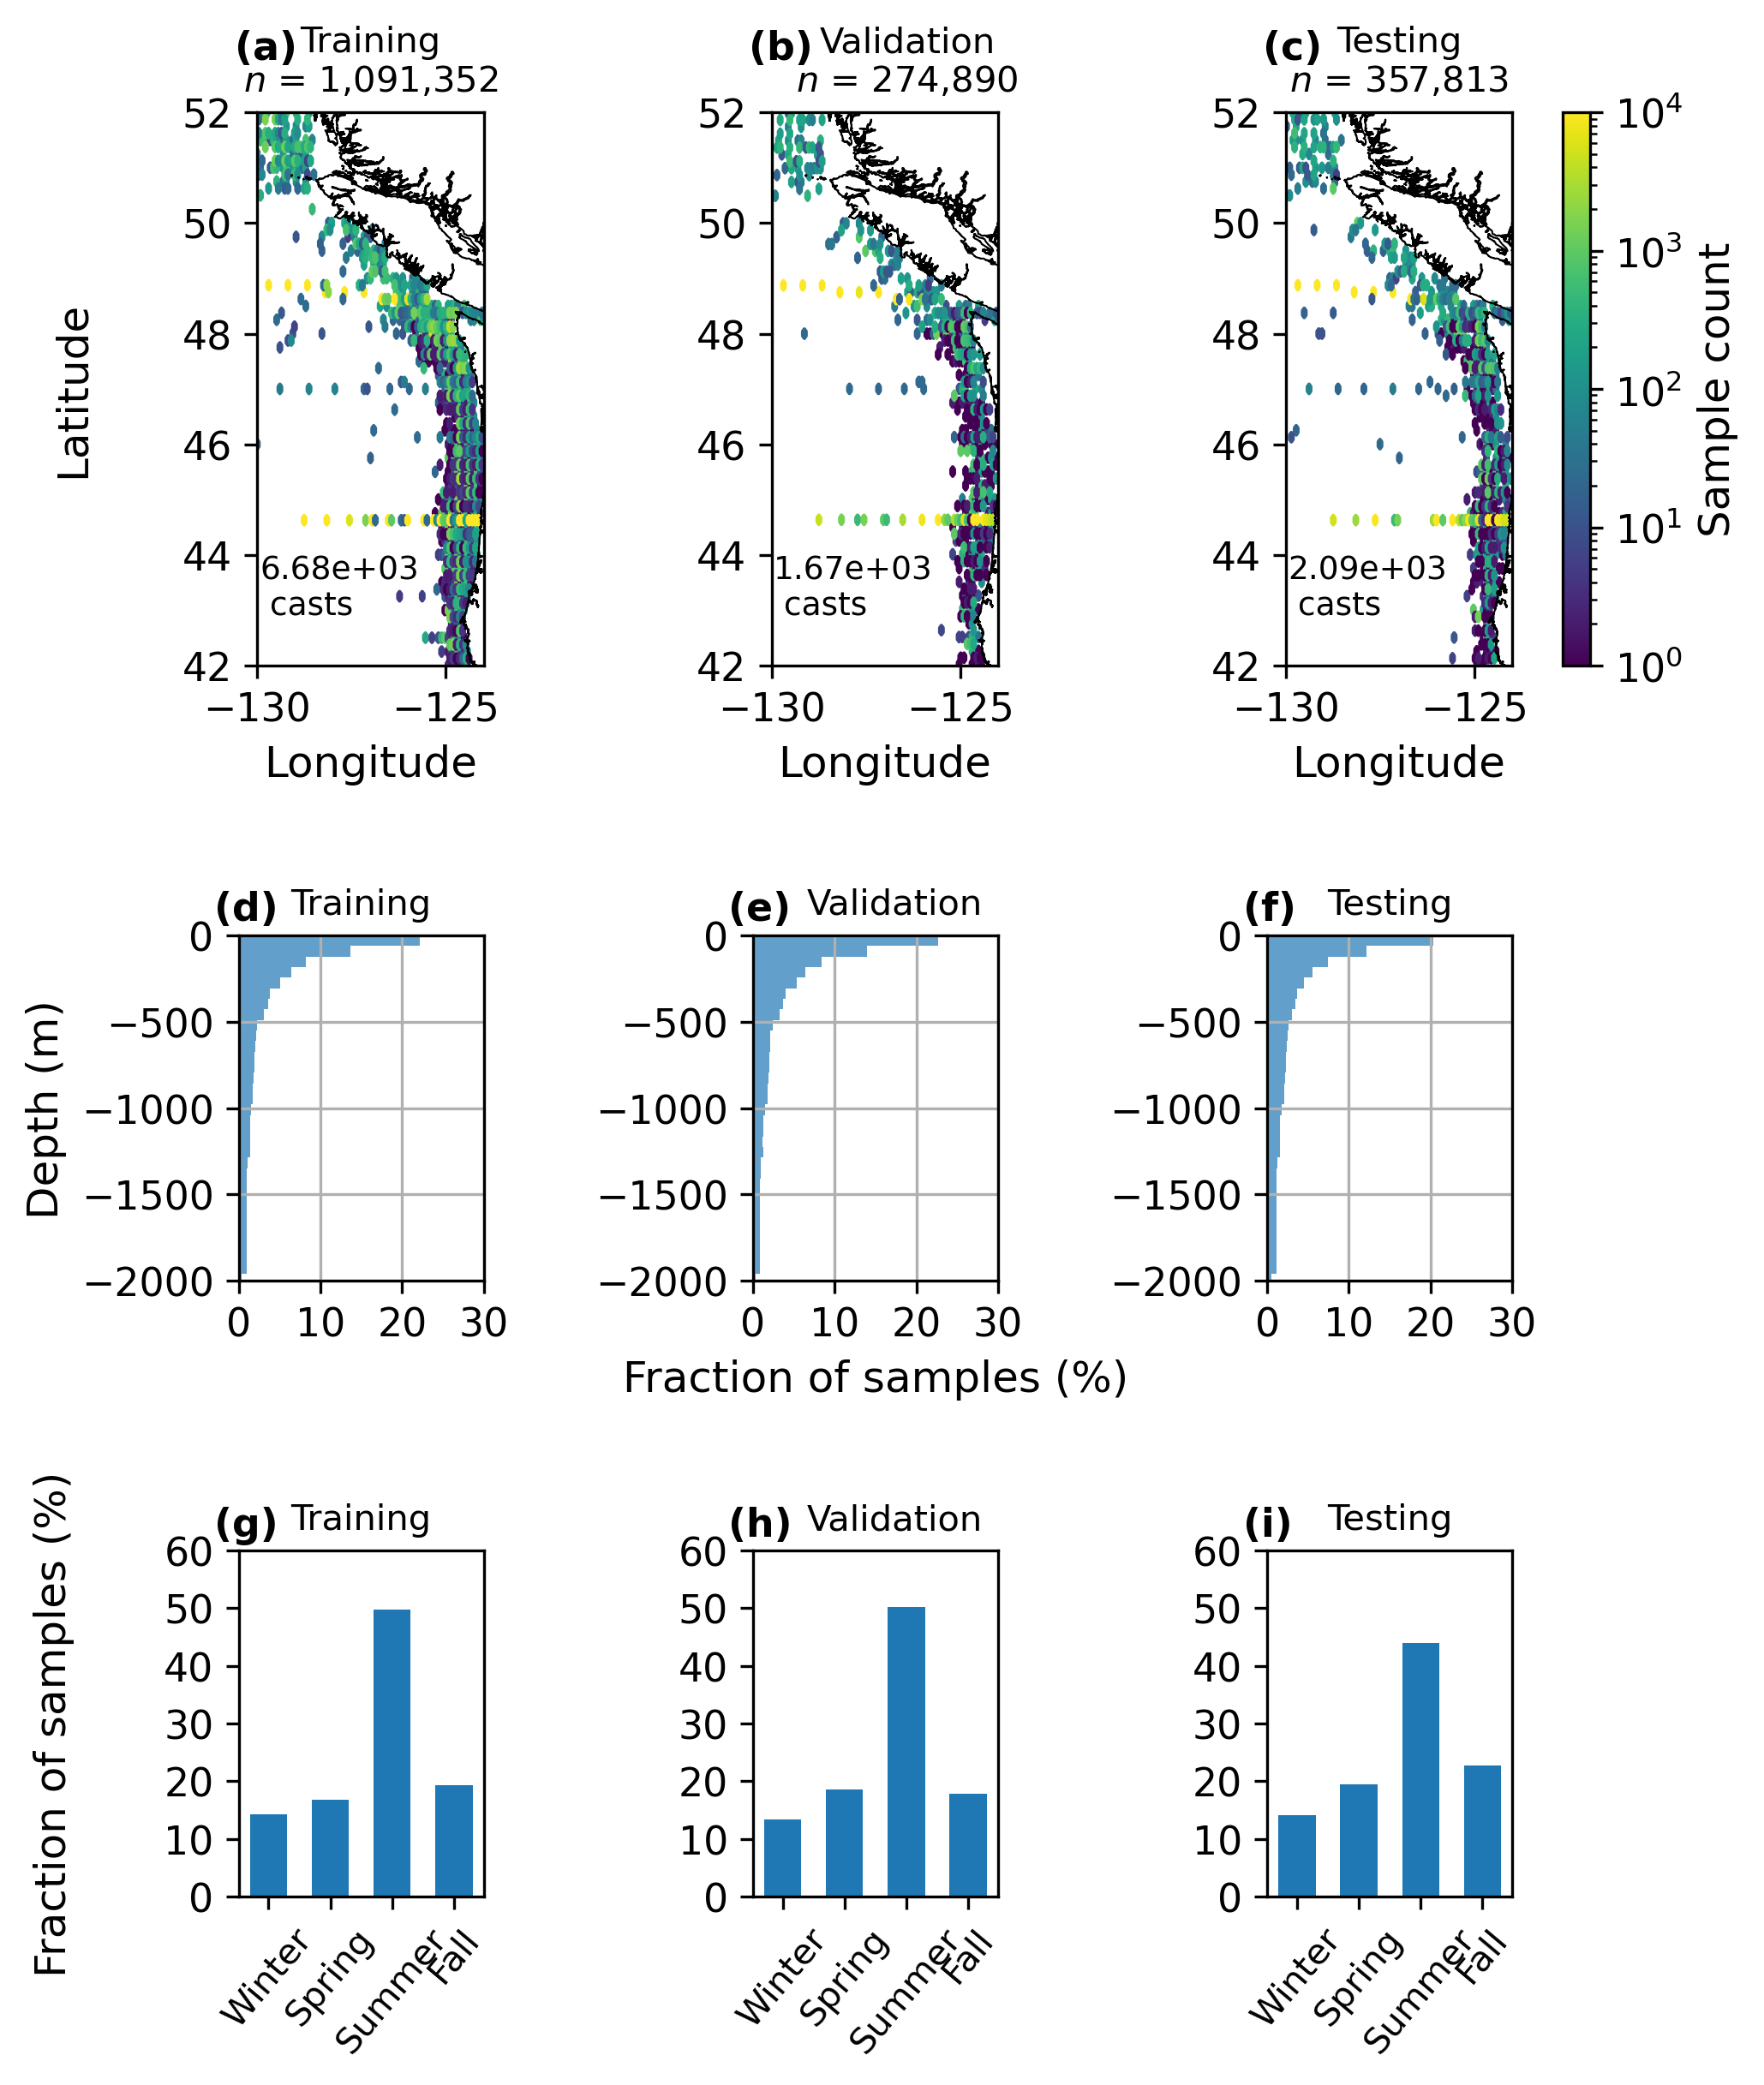

In [48]:
# ------------------------------------------------------------
# Prepare the three subsets
# ------------------------------------------------------------
subsets = {
    'Training': X_train2.copy(),
    'Validation': X_val.copy(),
    'Testing': X_test.copy()
}

# Convert time to datetime if needed
for name, df in subsets.items():

    # If time is already datetime, this leaves it unchanged.
    # If it is a date string, it converts it to datetime.
    df['time'] = pd.to_datetime(df['time'])

    # Add month and season
    df['month'] = df['time'].dt.month

    df['season'] = pd.cut(
        df['month'],
        bins=[0, 2, 5, 8, 11, 12],
        labels=['Winter', 'Spring', 'Summer', 'Fall', 'Winter'],
        ordered=False
    )

    subsets[name] = df


# ------------------------------------------------------------
# Common plotting settings
# ------------------------------------------------------------
fig, axes = plt.subplots(
    3, 3,
    figsize=(6.75, 8),
    dpi=300,
    constrained_layout=True,
    gridspec_kw={
        'height_ratios': [1.6, 1, 1],
        'hspace': 0.15,
        'wspace': 0.15
    }
)

subset_names = ['Training', 'Validation', 'Testing']

# Use identical limits for all three subsets
all_lon = pd.concat([subsets[k]['lon'] for k in subset_names])
all_lat = pd.concat([subsets[k]['lat'] for k in subset_names])
all_z = pd.concat([subsets[k]['z'] for k in subset_names])

lon_lim = (all_lon.min(), all_lon.max())
lat_lim = (all_lat.min(), all_lat.max())

# Use common depth bins
depth_bins = np.linspace(
    all_z.min(),
    all_z.max(),
    50
)

season_order = ['Winter', 'Spring', 'Summer', 'Fall']


# ------------------------------------------------------------
# Row 1: Spatial coverage
# ------------------------------------------------------------
common_norm = LogNorm(vmin=1, vmax=1e4)
for col, name in enumerate(subset_names):

    df = subsets[name]
    ax = axes[0, col]

    hb = ax.hexbin(
        df['lon'],
        df['lat'],
        gridsize=70,
        mincnt=1,
        norm=common_norm,
        cmap='viridis'
    )

    ax.set_xlim(lon_lim)
    ax.set_ylim(42,52)
    if name == 'Validation':
        ax.set_title(f'{name}\n$n$ = {len(df):,}', fontsize=10, x=0.6)
    else:
        ax.set_title(f'{name}\n$n$ = {len(df):,}',fontsize=10)
    ax.text(
    0.01, 0.2,
    f"{df['cid'].nunique():.2e}\n casts",
    # f"median = {np.median(df['bias']):.0f}",
    transform=ax.transAxes,
    va='top',
    fontsize=9,
    # fontweight='bold',
    )
    pfun.add_coast(ax)
    pfun.dar(ax)
    ax.set_xlabel('Longitude')
    if col == 0:
        ax.set_ylabel('Latitude', labelpad=25)

cbar = fig.colorbar(
    hb,
    ax=axes[0, :],
    orientation='vertical',
    fraction=0.025,
    pad=0.02
)

cbar.set_label('Sample count')

# ------------------------------------------------------------
# Row 2: Normalized depth distributions
# ------------------------------------------------------------
for col, name in enumerate(subset_names):

    df = subsets[name]
    ax = axes[1, col]

    ax.hist(
        -df['z'].dropna(),
        bins=np.linspace(-3000, 0, 50),
        weights=100 * (np.ones(df['z'].dropna().shape[0]) /
                df['z'].dropna().shape[0]),
        orientation='horizontal',
        histtype='stepfilled',
        alpha=0.7
    )
    ax.set_ylim(-2000, 0)
    # ax.set_ylim(data['z'].min(), 0)
    if col == 0:
        ax.set_ylabel('Depth (m)')
    if col == 1:
        ax.set_xlabel('Fraction of samples (%)')
    ax.set_xticks(np.arange(0, 30.01, 10))
    ax.set_xticklabels(['0',  '10', '20','30'])
    if name == 'Validation':
        ax.set_title(f'{name}', fontsize=10, x=0.58)
    else:
        ax.set_title(f'{name}',fontsize=10)
    ax.grid(True)

# ------------------------------------------------------------
# Row 3: Seasonal coverage
# ------------------------------------------------------------
for col, name in enumerate(subset_names):

    df = subsets[name]
    ax = axes[2, col]

    season_fraction = (
        df['season']
        .value_counts(normalize=True)
        .reindex(season_order)
        .fillna(0)
        * 100
    )

    ax.bar(
        season_order,
        season_fraction.values,
        width=0.6,
            )

    # ax.set_xlabel('Season')
    if col == 0:
        ax.set_ylabel('Fraction of samples (%)', labelpad=25)
    if name == 'Validation':
        ax.set_title(f'{name}', fontsize=10, x=0.58)
    else:
        ax.set_title(f'{name}',fontsize=10)

    ax.set_ylim(
        0,
        60
    )
    ax.set_yticks(np.arange(0, 60.01, 10))
    # ax.set_yticklabels(['0',  '10', '20','30'])
    # ax.grid(True, which='major',axis='y')
    ax.tick_params(axis='x', labelsize=10, rotation=50)

    # for label in ax.get_xticklabels():
    #     label.set_rotation(35)
    #     label.set_ha('right')
    #     label.set_rotation_mode('anchor')

# ------------------------------------------------------------
# Panel labels
# ------------------------------------------------------------
panel_labels = [
    '(a)', '(b)', '(c)',
    '(d)', '(e)', '(f)',
    '(g)', '(h)', '(i)'
]

for i, (ax, label) in enumerate(zip(axes.flat, panel_labels)):
    row = i // 3
    if row == 0:
        ax.text(
            -0.1,
            1.15,
            label,
            transform=ax.transAxes,
            fontsize=11,
            fontweight='bold',
            va='top',
            ha='left'
        )
    else:
        ax.text(
            -0.1,
            1.13,
            label,
            transform=ax.transAxes,
            fontsize=11,
            fontweight='bold',
            va='top',
            ha='left'
        )


# plt.tight_layout()
plt.savefig(
    f'{fig_dir}/Figure_S1_dataset_split_coverage_{runame}_{name}.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

In [44]:
year_dist = pd.DataFrame({
    'Training': (
        X_train2['time'].dt.year
        .value_counts(normalize=True)
        .sort_index() * 100
    ),
    'Validation': (
        X_val['time'].dt.year
        .value_counts(normalize=True)
        .sort_index() * 100
    ),
    'Testing': (
        X_test['time'].dt.year
        .value_counts(normalize=True)
        .sort_index() * 100
    )
})

print(year_dist.round(2))

      Training  Validation  Testing
time                               
1993      0.00        0.01     0.01
1994      0.03        0.06     0.05
1995      0.01        0.01     0.00
1996      0.01        0.01     0.01
1997      0.03        0.03     0.03
1998      0.88        1.60     1.81
1999      1.31        1.16     1.33
2000      1.35        0.96     1.28
2001      1.33        0.54     1.39
2002      1.66        1.50     3.42
2003      0.66        1.72     0.47
2004      1.18        1.07     1.21
2005      1.00        0.89     0.71
2006      3.33        1.18     4.24
2007      4.81        4.08     3.72
2008      5.78        5.43     2.84
2009      5.68        5.42     5.53
2010      5.90        4.96     5.94
2011      8.08        8.74     8.17
2012      4.79        6.01     9.30
2013      5.69        4.48     5.24
2014      5.53        5.99     3.50
2015      8.72        8.23     7.67
2016      5.64        5.87     4.70
2017      6.77        5.52     3.71
2018      6.44        6.97  

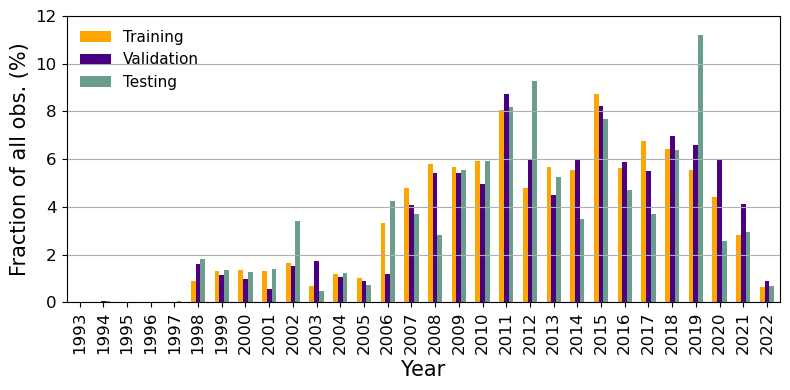

In [51]:
fig, ax = plt.subplots(figsize=(8, 4))

year_dist.plot(
    kind='bar',
    ax=ax,
    width=0.6,
    color=['orange','indigo','#6A9D8B'] # '#D88732',
)

ax.set_xlabel('Year', fontsize=15)
ax.set_ylabel('Fraction of all obs. (%)', fontsize=15)
ax.tick_params(axis='both', labelsize=12)
ax.set_ylim([0, 12])
ax.legend(frameon=False, fontsize=11)
ax.grid(True, which='major', axis='y')
plt.tight_layout()
plt.savefig(
    f'{fig_dir}/Figure_S*_dataset_split_temporal_{runame}_{name}.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()